In [ ]:
import shutil
from pathlib import Path
from google.colab import drive

# Safely remove local conflicting directory if it is not actually mounted yet
mount_path = Path('/content/drive')
if mount_path.exists() and not mount_path.is_mount():
    print(f"Removing conflicting local directory: {mount_path}")
    shutil.rmtree(mount_path)

# Mount the drive
drive.mount('/content/drive', force_remount=True)

Removing conflicting local directory: /content/drive
Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

base_dir = Path("/content/drive/MyDrive/MVJ_Internship")

day12_dir = base_dir / "Project1" / "day12_data_cleaning"
day13_dir = base_dir / "Project1" / "day13_customer_analytics"

day13_dir.mkdir(parents=True, exist_ok=True)

cleaned_file = day12_dir / "cleaned_sales.csv"

print("Day 12 file exists:", cleaned_file.exists())
print("Day 13 output folder:", day13_dir)

Day 12 file exists: True
Day 13 output folder: /content/drive/MyDrive/MVJ_Internship/Project1/day13_customer_analytics


In [ ]:
#load and inspect the cleaned dataset
sales = pd.read_csv(cleaned_file, parse_dates=["InvoiceDate"])

print("Dataset shape:", sales.shape)
print("\nColumns:")
print(sales.columns.tolist())

display(sales.head())

/tmp/ipykernel_1881/1220611753.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  sales = pd.read_csv(cleaned_file, parse_dates=["InvoiceDate"])


Dataset shape: (1007911, 12)

Columns:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue', 'Is_Cancellation_Invoice', 'Is_Negative_Quantity', 'Is_Revenue_Outlier']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Is_Cancellation_Invoice,Is_Negative_Quantity,Is_Revenue_Outlier
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01,6.95,13085.0,United Kingdom,83.4,False,False,True
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01,6.75,13085.0,United Kingdom,81.0,False,False,True
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01,6.75,13085.0,United Kingdom,81.0,False,False,True
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01,2.10,13085.0,United Kingdom,100.8,False,False,True
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01,1.25,13085.0,United Kingdom,30.0,False,False,False


In [ ]:
# Validate the fields needed for customer analysis

required_columns = [
    "Invoice",
    "InvoiceDate",
    "Customer ID",
    "Quantity",
    "Price",
    "Revenue"
]

missing_columns = [
    col for col in required_columns if col not in sales.columns
]

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

print("Missing required columns:", missing_columns)
print("\nMissing customer IDs:", sales["Customer ID"].isna().sum())
print("Missing invoice dates:", sales["InvoiceDate"].isna().sum())
print("Date range:", sales["InvoiceDate"].min(), "to", sales["InvoiceDate"].max())

Missing required columns: []

Missing customer IDs: 228488
Missing invoice dates: 0
Date range: 2009-12-01 00:00:00 to 2011-12-09 00:00:00


In [ ]:
# Prepare the customer transaction data

# Prepare valid transactions

sales["Customer ID"] = pd.to_numeric(
    sales["Customer ID"], errors="coerce"
)

sales["Quantity"] = pd.to_numeric(
    sales["Quantity"], errors="coerce"
)

sales["Price"] = pd.to_numeric(
    sales["Price"], errors="coerce"
)

sales["Revenue"] = pd.to_numeric(
    sales["Revenue"], errors="coerce"
)

customer_sales = sales[
    sales["Customer ID"].notna()
    & sales["InvoiceDate"].notna()
    & sales["Quantity"].gt(0)
    & sales["Price"].gt(0)
    & sales["Revenue"].notna()
].copy()

# Exclude cancellation invoices if the flag exists
if "Is_Cancellation_Invoice" in customer_sales.columns:
    customer_sales = customer_sales[
        ~customer_sales["Is_Cancellation_Invoice"].astype(bool)
    ].copy()

# Keep only positive sales revenue
customer_sales = customer_sales[
    customer_sales["Revenue"] > 0
].copy()

print("Rows in Day 12 cleaned dataset:", len(sales))
print("Valid customer transaction rows:", len(customer_sales))
print("Unique customers:", customer_sales["Customer ID"].nunique())

Rows in Day 12 cleaned dataset: 1007911
Valid customer transaction rows: 779423
Unique customers: 5878


In [ ]:
#calculate RFM Metrics and scores

analysis_date = (
    customer_sales["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = (
    customer_sales.groupby("Customer ID")
    .agg(
        Last_Purchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

rfm["Recency"] = (
    analysis_date - rfm["Last_Purchase"].dt.normalize()
).dt.days

print("Analysis reference date:", analysis_date.date())
print("Customers in RFM table:", len(rfm))

display(rfm.head())

Analysis reference date: 2011-12-10
Customers in RFM table: 5878


,Customer ID,Last_Purchase,Frequency,Monetary,Recency
0,12346.0,2011-01-18,12,77556.46,326
1,12347.0,2011-12-07,8,4921.53,3
2,12348.0,2011-09-25,5,2019.40,76
3,12349.0,2011-11-21,4,4428.69,19
4,12350.0,2011-02-02,1,334.40,311


In [ ]:
#assign RFM scores

# Recency: recent buyers get higher scores
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: frequent buyers get higher scores
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher spenders get higher scores
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.head(10))

,Customer ID,Last_Purchase,Frequency,Monetary,Recency,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,2011-01-18,12,77556.46,326,2,5,5,255
1,12347.0,2011-12-07,8,4921.53,3,5,4,5,545
2,12348.0,2011-09-25,5,2019.40,76,3,4,4,344
3,12349.0,2011-11-21,4,4428.69,19,5,3,5,535
4,12350.0,2011-02-02,1,334.40,311,2,1,2,212
5,12351.0,2010-11-29,1,300.93,376,2,1,2,212
6,12352.0,2011-11-03,10,2849.84,37,4,5,4,454
7,12353.0,2011-05-19,2,406.76,205,2,2,2,222
8,12354.0,2011-04-21,1,1079.40,233,2,1,3,213
9,12355.0,2011-05-09,2,947.61,215,2,2,3,223


In [ ]:
#create customer segments based on the RFM scores that are calculated.

def assign_segment(row):
    if row["R_Score"] >= 4 and row["F_Score"] >= 4 and row["M_Score"] >= 4:
        return "High-Value Loyal"
    elif row["R_Score"] >= 4 and row["F_Score"] >= 3:
        return "Recent and Active"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 4:
        return "Frequent Customers"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "At-Risk Customers"
    elif row["R_Score"] >= 4 and row["F_Score"] <= 2:
        return "New or Promising"
    else:
        return "Other Customers"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("Segment")
    .agg(
        Customers=("Customer ID", "nunique"),
        Total_Revenue=("Monetary", "sum"),
        Average_Recency_Days=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean")
    )
    .reset_index()
    .sort_values("Total_Revenue", ascending=False)
)

segment_summary["Revenue_Share_Pct"] = (
    segment_summary["Total_Revenue"]
    / segment_summary["Total_Revenue"].sum()
    * 100
).round(2)

display(segment_summary)

,Segment,Customers,Total_Revenue,Average_Recency_Days,Average_Frequency,Revenue_Share_Pct
2,High-Value Loyal,1289,1.183075e+07,20.207913,17.147401,68.09
1,Frequent Customers,525,1.721600e+06,106.043810,8.558095,9.91
0,At-Risk Customers,824,1.589703e+06,369.641990,4.940534,9.15
4,Other Customers,2178,1.199559e+06,354.593664,1.505510,6.90
5,Recent and Active,621,6.411399e+05,24.780998,3.830918,3.69
3,New or Promising,441,3.920216e+05,28.510204,1.462585,2.26


BUILD COHORT RETENTION MAATRIX

In [ ]:
#assign each customer's cohort month

cohort_data = customer_sales.copy()

cohort_data["InvoiceMonth"] = (
    cohort_data["InvoiceDate"].dt.to_period("M")
)

first_purchase = (
    cohort_data.groupby("Customer ID")["InvoiceMonth"]
    .min()
    .rename("CohortMonth")
)

cohort_data = cohort_data.join(
    first_purchase,
    on="Customer ID"
)

cohort_data["CohortIndex"] = (
    (cohort_data["InvoiceMonth"].dt.year
     - cohort_data["CohortMonth"].dt.year) * 12
    + (cohort_data["InvoiceMonth"].dt.month
       - cohort_data["CohortMonth"].dt.month)
    + 1
)

display(
    cohort_data[
        ["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex"]
    ].head()
)

,Customer ID,InvoiceMonth,CohortMonth,CohortIndex
0,13085.0,2009-12,2009-12,1
1,13085.0,2009-12,2009-12,1
2,13085.0,2009-12,2009-12,1
3,13085.0,2009-12,2009-12,1
4,13085.0,2009-12,2009-12,1


In [ ]:
# Calculate cohort active customer counts
cohort_counts = (
    cohort_data.groupby(["CohortMonth", "CohortIndex"])
    ["Customer ID"].nunique()
    .reset_index()
    .pivot(index="CohortMonth", columns="CohortIndex", values="Customer ID")
)

# Convert counts to retention percentages
cohort_sizes = cohort_counts.iloc[:, 0]

cohort_retention = cohort_counts.divide(
    cohort_sizes, axis=0
) * 100

cohort_retention = cohort_retention.round(2)

print("Cohort retention matrix (%):")
display(cohort_retention)

Cohort retention matrix (%):


CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,100.0,35.29,33.40,42.51,38.01,35.92,37.70,34.24,33.61,36.23,...,30.26,26.28,30.26,28.27,25.97,25.55,31.52,30.47,40.73,19.69
2010-01,100.0,20.63,31.07,30.55,26.37,30.03,25.85,22.98,27.94,31.85,...,15.14,23.50,19.84,18.54,19.58,24.28,19.32,24.54,5.74,NaN
2010-02,100.0,23.80,22.46,29.14,24.60,20.05,19.25,28.61,25.40,27.54,...,20.05,16.04,16.31,14.44,22.99,22.99,16.31,5.88,NaN,NaN
2010-03,100.0,18.96,23.02,24.15,23.25,20.32,24.60,30.25,27.54,10.84,...,16.93,17.38,15.58,17.61,20.09,21.22,7.90,NaN,NaN,NaN
2010-04,100.0,19.39,19.39,16.33,18.37,22.45,27.55,26.19,10.54,10.88,...,15.65,13.95,14.97,18.03,22.45,5.78,NaN,NaN,NaN,NaN
2010-05,100.0,15.75,16.93,17.32,17.72,25.59,21.26,12.60,5.91,8.27,...,12.60,13.78,16.54,15.35,4.72,NaN,NaN,NaN,NaN,NaN
2010-06,100.0,17.41,18.89,20.37,22.96,28.52,12.59,8.89,8.15,11.85,...,12.22,13.33,20.37,5.19,NaN,NaN,NaN,NaN,NaN,NaN
2010-07,100.0,15.59,18.28,29.57,29.03,13.98,11.29,14.52,14.52,11.29,...,17.20,23.66,8.06,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2010-08,100.0,20.37,29.63,32.10,17.28,11.73,9.88,12.35,13.58,12.96,...,19.75,6.79,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


CREATE THE HEATMAP

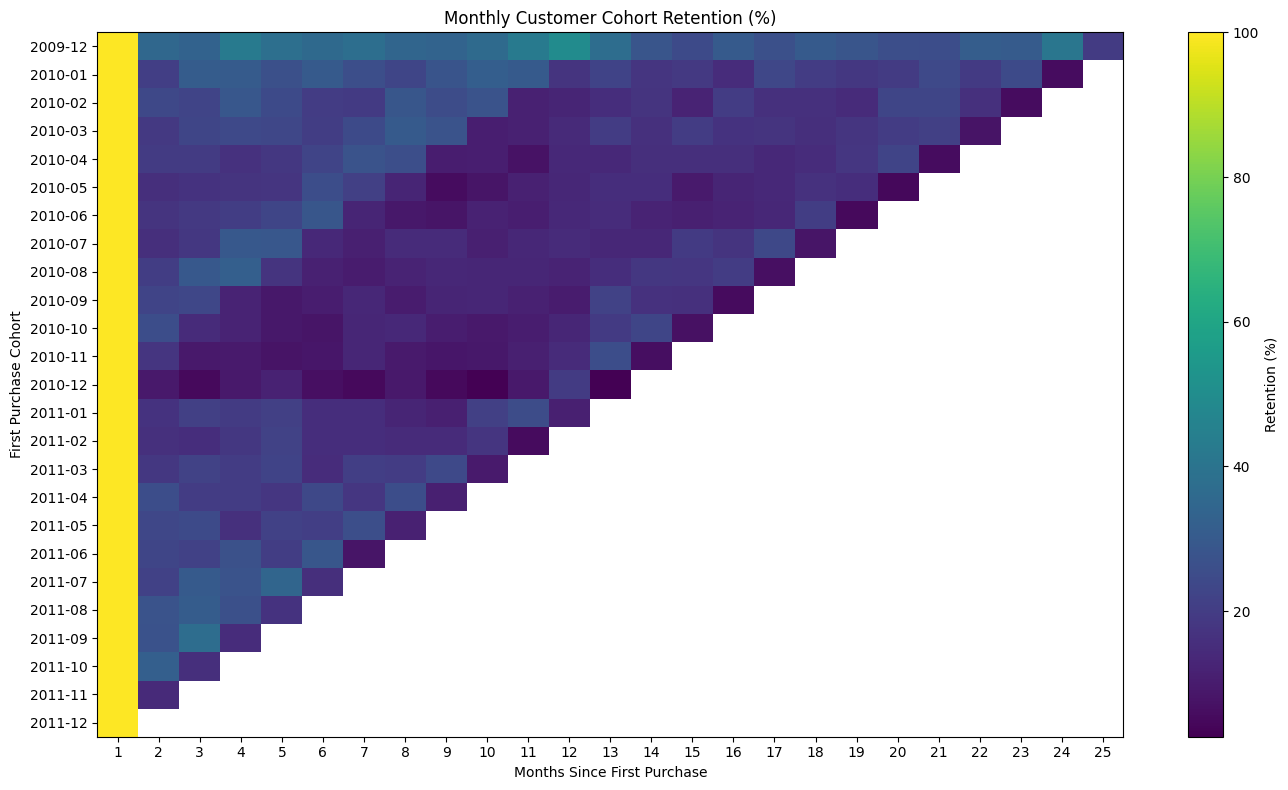

Heatmap saved to: /content/drive/MyDrive/MVJ_Internship/Project1/day13_customer_analytics/cohort_retention_heatmap.png


In [ ]:
# Plot and save the retention heatmap

fig, ax = plt.subplots(figsize=(14, 8))

im = ax.imshow(
    cohort_retention,
    aspect="auto",
    interpolation="nearest"
)

ax.set_title("Monthly Customer Cohort Retention (%)")
ax.set_xlabel("Months Since First Purchase")
ax.set_ylabel("First Purchase Cohort")

ax.set_xticks(range(len(cohort_retention.columns)))
ax.set_xticklabels(cohort_retention.columns)

ax.set_yticks(range(len(cohort_retention.index)))
ax.set_yticklabels(cohort_retention.index)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Retention (%)")

plt.tight_layout()

heatmap_path = day13_dir / "cohort_retention_heatmap.png"
plt.savefig(heatmap_path, dpi=150, bbox_inches="tight")
plt.show()

print("Heatmap saved to:", heatmap_path)

Save the outputs and write findings

In [ ]:
#SAVE THE ANALYSIS FILES

rfm.to_csv(
    day13_dir / "customer_rfm_scores.csv",
    index=False
)

segment_summary.to_csv(
    day13_dir / "rfm_segment_summary.csv",
    index=False
)

cohort_counts.to_csv(
    day13_dir / "cohort_customer_counts.csv"
)

cohort_retention.to_csv(
    day13_dir / "cohort_retention_matrix.csv"
)

print("Saved Day 13 outputs:")
for file_path in sorted(day13_dir.iterdir()):
    print("-", file_path.name)

Saved Day 13 outputs:
- cohort_customer_counts.csv
- cohort_retention_heatmap.png
- cohort_retention_matrix.csv
- customer_rfm_scores.csv
- rfm_segment_summary.csv


In [ ]:
#generate a few evidence-based findings

print("DAY 13 CUSTOMER ANALYTICS FINDINGS")
print("-" * 40)

print("Unique customers analysed:", rfm["Customer ID"].nunique())
print("Total positive sales revenue:", round(rfm["Monetary"].sum(), 2))

print("\nCustomer segments:")
display(segment_summary)

if 2 in cohort_retention.columns:
    month_2 = cohort_retention[2].dropna()
    if not month_2.empty:
        print(
            "\nAverage month-2 retention across eligible cohorts:",
            round(month_2.mean(), 2), "%"
        )

print("\nTop 5 customers by total positive revenue:")
display(
    rfm.sort_values("Monetary", ascending=False)[
        ["Customer ID", "Recency", "Frequency", "Monetary", "Segment"]
    ].head(5)
)

DAY 13 CUSTOMER ANALYTICS FINDINGS
----------------------------------------
Unique customers analysed: 5878
Total positive sales revenue: 17374770.67

Customer segments:


,Segment,Customers,Total_Revenue,Average_Recency_Days,Average_Frequency,Revenue_Share_Pct
2,High-Value Loyal,1289,1.183075e+07,20.207913,17.147401,68.09
1,Frequent Customers,525,1.721600e+06,106.043810,8.558095,9.91
0,At-Risk Customers,824,1.589703e+06,369.641990,4.940534,9.15
4,Other Customers,2178,1.199559e+06,354.593664,1.505510,6.90
5,Recent and Active,621,6.411399e+05,24.780998,3.830918,3.69
3,New or Promising,441,3.920216e+05,28.510204,1.462585,2.26



Average month-2 retention across eligible cohorts: 21.17 %

Top 5 customers by total positive revenue:


,Customer ID,Recency,Frequency,Monetary,Segment
5692,18102.0,1,145,580987.04,High-Value Loyal
2277,14646.0,2,151,528602.52,High-Value Loyal
1789,14156.0,10,156,313437.62,High-Value Loyal
2538,14911.0,2,398,291420.81,High-Value Loyal
5050,17450.0,9,51,244784.25,High-Value Loyal


In [ ]:
#check all the deliverables

expected_files = [
    "customer_rfm_scores.csv",
    "rfm_segment_summary.csv",
    "cohort_customer_counts.csv",
    "cohort_retention_matrix.csv",
    "cohort_retention_heatmap.png"
]

print("FINAL DAY 13 FILE CHECK")
for filename in expected_files:
    path = day13_dir / filename
    print(f"{filename}: {'OK' if path.exists() else 'MISSING'}")

print("\nRFM rows:", len(rfm))
print("Unique customer IDs in RFM:", rfm["Customer ID"].nunique())
print("Cohort retention matrix shape:", cohort_retention.shape)
print(
    "Retention values within 0–100%:",
    bool(
        cohort_retention.stack().between(0, 100).all()
    )
)

FINAL DAY 13 FILE CHECK
customer_rfm_scores.csv: OK
rfm_segment_summary.csv: OK
cohort_customer_counts.csv: OK
cohort_retention_matrix.csv: OK
cohort_retention_heatmap.png: OK

RFM rows: 5878
Unique customer IDs in RFM: 5878
Cohort retention matrix shape: (25, 25)
Retention values within 0–100%: True
